1. Carga de datos
Cargamos la tabla maestra de prospección pesquera (T_Maestra_Prov.xlsx) desde el repositorio. Este archivo contiene registros de faenas de pesca artesanal en San Andrés y Providencia.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Instalar openpyxl solo si hace falta (ejecutar una sola vez)
!pip install openpyxl -q

In [5]:
# Cargar datos desde el repositorio
df = pd.read_excel("Data/T_Maestra_Prov.xlsx")

print(f"Datos cargados: {df.shape[0]} filas y {df.shape[1]} columnas")
df.head()

Datos cargados: 11032 filas y 33 columnas


,CODIGO,REGISTRO,ARTE,METODO,ANO_ZARPE,MES_ZARPE,DIA_ZARPE,ANO_ARRIBO,MES_ARRIBO,DIA_ARRIBO,...,GRUPO,SUBGRUPO,Clasificacio,NOM_CIENTIF,NOM_VULGAR,ESTADO,PESO,CT_KG,GASTOS,CPUE
0,12080001,1,BUCEO,NaN,2012,8,6,2012,8,6,...,PECES,OTROS PELÁGICOS,ROJO,Sphyraena barracuda,BARRACUDA,EVISC CON ESCAMA,2.0,21.5,60500.0,2.0
1,12080001,1,BUCEO,NaN,2012,8,6,2012,8,6,...,PECES,DEMERSAL SOMERO,ROJO,Mycteroperca bonaci,BLACK GROUPER,EVISC CON ESCAMA,3.5,NaN,NaN,3.5
2,12080001,1,BUCEO,NaN,2012,8,6,2012,8,6,...,PECES,DEMERSAL SOMERO,ROJO,Lutjanus jocu,DOGTEETH SNAPPER,EVISC CON ESCAMA,5.0,NaN,NaN,5.0
3,12080001,1,BUCEO,NaN,2012,8,6,2012,8,6,...,PECES,DEMERSAL SOMERO,ROJO,Lachnolaimus maximus,HOG FISH,EVISC CON ESCAMA,4.0,NaN,NaN,4.0
4,12080001,1,BUCEO,NaN,2012,8,6,2012,8,6,...,PECES,DEMERSAL SOMERO,ROJO,Haemulon album,MARGATE,EVISC CON ESCAMA,2.5,NaN,NaN,2.5


*2. Definición de funciones sencillas*
Definimos dos funciones reutilizables:

Una para obtener un resumen estadístico rápido de una variable numérica.
Otra para generar simultáneamente un histograma y un boxplot.

Python

In [6]:
def resumen_variable(data, columna):
    """Muestra estadísticas básicas de una columna numérica."""
    print(f"=== Resumen de {columna} ===")
    print(data[columna].describe())
    print(f"Valores nulos: {data[columna].isna().sum()}\n")


def graficar_hist_box(data, columna, color="steelblue"):
    """Crea histograma y boxplot lado a lado para una variable numérica."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    sns.histplot(data[columna].dropna(), ax=axes[0], color=color, kde=True)
    axes[0].set_title(f"Histograma de {columna}")
    
    sns.boxplot(x=data[columna].dropna(), ax=axes[1], color=color)
    axes[1].set_title(f"Boxplot de {columna}")
    
    plt.tight_layout()
    plt.show()

3. Aplicación de las funciones
Aplicamos las funciones definidas sobre las variables PESO y CPUE.

=== Resumen de PESO ===
count    11032.000000
mean        16.338809
std        201.857748
min          0.000000
25%          2.000000
50%          5.000000
75%         11.000000
max      18000.000000
Name: PESO, dtype: float64
Valores nulos: 0

=== Resumen de CPUE ===
count    11032.000000
mean        12.217435
std         94.394873
min          0.000000
25%          2.000000
50%          5.000000
75%         11.000000
max       7075.000000
Name: CPUE, dtype: float64
Valores nulos: 0



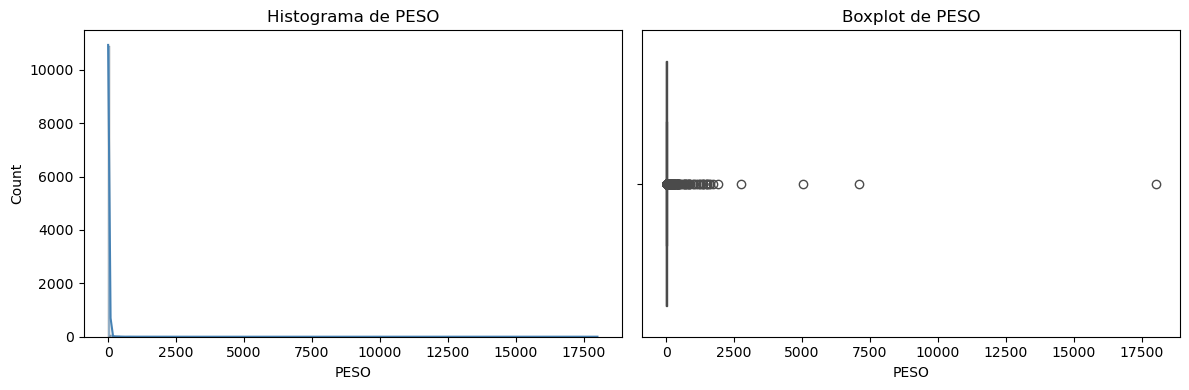

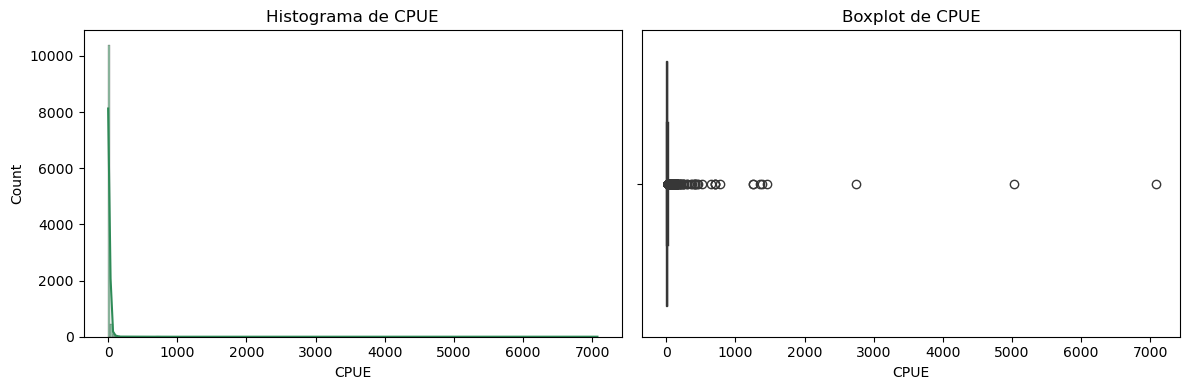

In [7]:
# Resúmenes estadísticos
resumen_variable(df, "PESO")
resumen_variable(df, "CPUE")

# Gráficos de histograma + boxplot
graficar_hist_box(df, "PESO")
graficar_hist_box(df, "CPUE", color="seagreen")

*4. Gráficos adicionales*
Visualizamos las especies más frecuentes y la relación entre peso y CPUE.

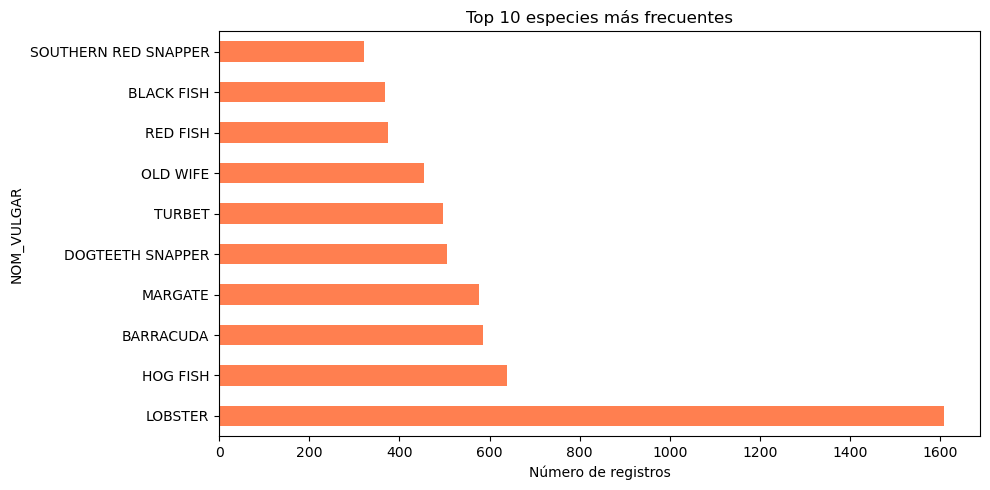

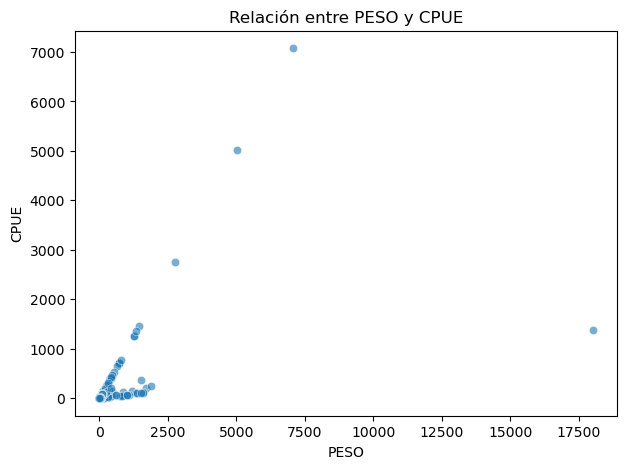

In [8]:
# Top 10 especies más frecuentes
plt.figure(figsize=(10, 5))
df["NOM_VULGAR"].value_counts().head(10).plot(kind="barh", color="coral")
plt.title("Top 10 especies más frecuentes")
plt.xlabel("Número de registros")
plt.tight_layout()
plt.show()

# Relación entre PESO y CPUE
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="PESO", y="CPUE", alpha=0.6)
plt.title("Relación entre PESO y CPUE")
plt.show()

*5. Explicacion*
Se cargaron los datos de prospección, se definieron funciones para resumen y visualización, y se generaron gráficos exploratorios de las principales variables numéricas y categóricas del dataset.